<a href="https://colab.research.google.com/github/Miranayy/DSCI100_009_019/blob/main/streetwear_real.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Getting the dataset

In [1]:
!pip install -q kagglehub
import kagglehub, os
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")
print(path)
print(os.listdir(path))

Using Colab cache for faster access to the 'fashion-product-images-small' dataset.
/kaggle/input/fashion-product-images-small
['myntradataset', 'images', 'styles.csv']


In [2]:
BASE = path
print(os.listdir(BASE))

['myntradataset', 'images', 'styles.csv']


Organizing the images into folders

In [3]:
import pandas as pd, shutil, random

df = pd.read_csv(os.path.join(BASE, "styles.csv"), on_bad_lines="skip")
mapping = {
    "Tshirts": "tshirts", "Sweatshirts": "hoodies", "Jackets": "jackets",
    "Jeans": "jeans", "Casual Shoes": "sneakers", "Sports Shoes": "sneakers", "Shirts": "shirts"
}
df = df[df["articleType"].isin(mapping)].copy()
df["label"] = df["articleType"].map(mapping)
print(df["label"].value_counts())

random.seed(42)
for label, group in df.groupby("label"):
  ids = group["id"].tolist()
  random.shuffle(ids)
  ids = ids[:1500]
  n = len(ids)
  splits = {"train": ids[:int(.7*n)], "val": ids[int(.7*n):int(.85*n)], "test": ids[int(.85*n):]}
  for split, split_ids in splits.items():
    dst = f"/content/data/{split}/{label}"
    os.makedirs(dst, exist_ok=True)
    for i in split_ids:
      src = os.path.join(BASE, "images", f"{i}.jpg")
      if os.path.exists(src):
        shutil.copy(src, dst)

for split in ["train", "val", "test"]:
  print(split, {c: len(os.listdir(f"/content/data/{split}/{c}")) for c in os.listdir(f"/content/data/{split}")})

label
tshirts     7067
sneakers    4881
shirts      3217
jeans        609
hoodies      285
jackets      258
Name: count, dtype: int64
train {'tshirts': 1050, 'shirts': 1050, 'hoodies': 199, 'jackets': 180, 'jeans': 425, 'sneakers': 1050}
val {'tshirts': 224, 'shirts': 225, 'hoodies': 43, 'jackets': 39, 'jeans': 91, 'sneakers': 225}
test {'tshirts': 225, 'shirts': 224, 'hoodies': 43, 'jackets': 39, 'jeans': 92, 'sneakers': 225}


Transfer learning


In [4]:
import torch
from torch import nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder("/content/data/train", train_tf)
val_ds = datasets.ImageFolder("/content/data/val", eval_tf)
test_ds = datasets.ImageFolder("/content/data/test", eval_tf)
classes = train_ds.classes
print(classes)

train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=32, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=32, num_workers=2)



['hoodies', 'jackets', 'jeans', 'shirts', 'sneakers', 'tshirts']


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s]


NameError: name 'train_one_epoch' is not defined

In [6]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()                       # turn on training mode
    total_loss, correct, n = 0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()           # 1. clear old gradients
        out = model(x)                  # 2. make predictions
        loss = criterion(out, y)        # 3. measure how wrong they are
        loss.backward()                 # 4. figure out how to adjust each weight (backpropagation)
        optimizer.step()                # 5. adjust the weights a little
        total_loss += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n

def evaluate(model, loader, criterion):
    model.eval()                        # turn off training-only behavior
    total_loss, correct, n = 0, 0, 0
    with torch.no_grad():               # don't track gradients, which is faster
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

In [8]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for p in model.parameters():
  p.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

counts = torch.bincount(torch.tensor(train_ds.targets))
weights = (counts.sum() / counts).float()
criterion = nn.CrossEntropyLoss(weight=(weights / weights.mean()).to(device))

optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

for epoch in range(5):
  tl, ta = train_one_epoch(model, train_dl, criterion, optimizer)
  vl, va = evaluate(model, val_dl, criterion)
  print(f"Epoch {epoch+1}: train acc {ta:.3f} | val acc {va:.3f}")

Epoch 1: train acc 0.725 | val acc 0.848
Epoch 2: train acc 0.845 | val acc 0.855
Epoch 3: train acc 0.858 | val acc 0.869
Epoch 4: train acc 0.862 | val acc 0.880
Epoch 5: train acc 0.882 | val acc 0.861


Test accuracy: 0.875


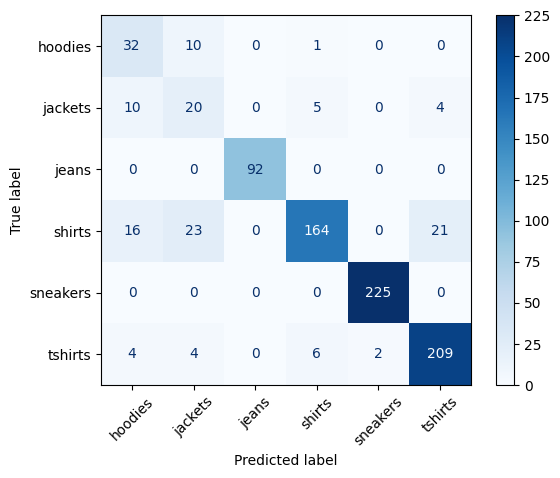

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def get_preds(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            preds.append(model(x.to(device)).argmax(1).cpu())
            labels.append(y)
    return torch.cat(preds), torch.cat(labels)

preds, labels = get_preds(model, test_dl)
print("Test accuracy:", (preds == labels).float().mean().item())

cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=test_ds.classes).plot(xticks_rotation=45, cmap="Blues")
plt.show()

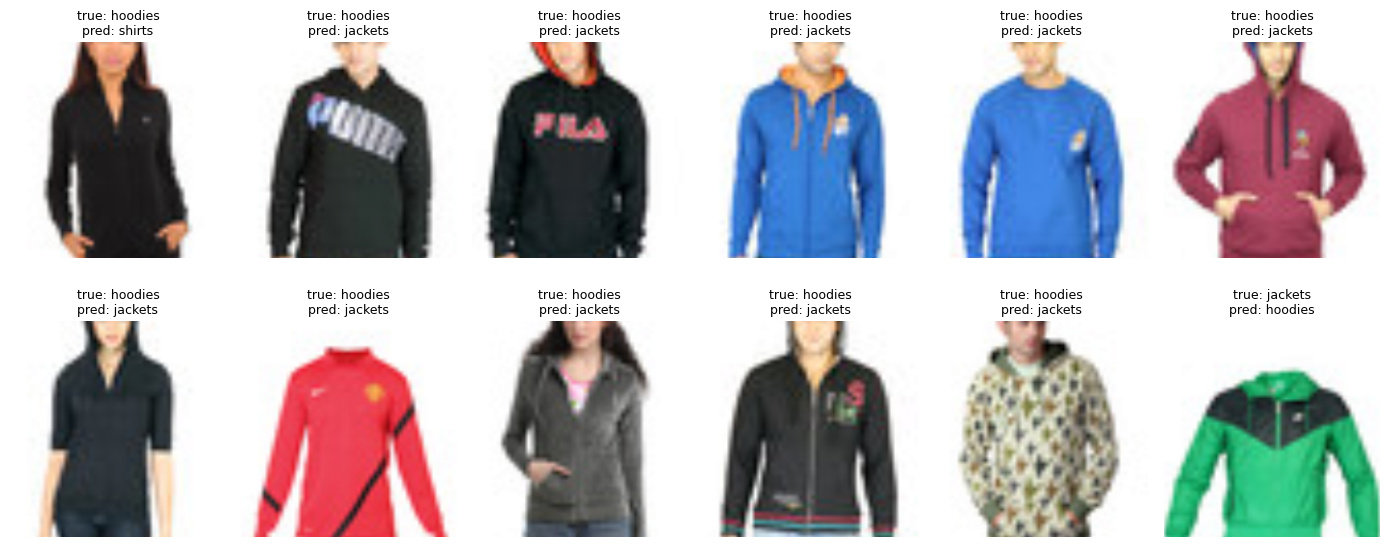

In [11]:
preds, labels = get_preds(model, test_dl)   # fresh predictions from your current model

def show(img_tensor):
    # undo the Normalize step so colors look right
    img = img_tensor.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)
    return img.clamp(0, 1)

# indexes of test images that are hoodies or jackets AND were predicted wrong (first 12)
hj = [i for i in (preds != labels).nonzero().flatten().tolist()
      if classes[labels[i]] in ("hoodies", "jackets")][:12]

fig, axes = plt.subplots(2, 6, figsize=(14, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, hj):
    img, _ = test_ds[i]
    ax.imshow(show(img))
    ax.set_title(f"true: {classes[labels[i]]}\npred: {classes[preds[i]]}", fontsize=9)
plt.tight_layout()
plt.show()

In [12]:
from google.colab import drive
import os
drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/streetwear', exist_ok=True)
print(os.path.exists('/content/drive/MyDrive/streetwear'))

Mounted at /content/drive
True


In [13]:
torch.save(model.state_dict(), "/content/drive/MyDrive/streetwear/resnet_clothing.pt")

In [14]:
for p in model.layer4.parameters():
  p.requires_grad = True

optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=1e-4)

for epoch in range(4):
  tl, ta = train_one_epoch(model, train_dl, criterion, optimizer)
  vl, va = evaluate(model, val_dl, criterion)
  print(f"Epoch {epoch+1}: train acc {ta:.3f} | val acc {va:.3f}")

torch.save(model.state_dict(), "/content/drive/MyDrive/streetwear/resnet_clothing.pt")

Epoch 1: train acc 0.905 | val acc 0.924
Epoch 2: train acc 0.952 | val acc 0.933
Epoch 3: train acc 0.964 | val acc 0.915
Epoch 4: train acc 0.971 | val acc 0.929


Fine-tune and evaluate

In [15]:
def show(img_tensor):
  img = img_tensor.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)
  return img.clamp(0, 1)

Testing on your own photos

In [16]:
from PIL import Image
import glob

model.eval()
for f in glob.glob("/content/*.jpg") + glob.glob("/content/*.png"):
  img = Image.open(f).convert("RGB")
  x = eval_tf(img).unsqueeze(0).to(device)
  with torch.no_grad():
    probs = torch.softmax(model(x), 1)[0]
  top = probs.argmax().item()
  plt.imshow(img); plt.title(f"{classes[top]} ({probs[top]:.0%})"); plt.axis("off"); plt.show()

In [17]:
!pip install -q gradio
import gradio as gr

def predict(img):
  x = eval_tf(img.convert("RGB")).unsqueeze(0).to(device)
  with torch.no_grad():
    probs = torch.softmax(model(x), 1)[0]
  return {c: float(p) for c, p in zip(classes, probs)}

gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=3),
    title="Streetwear Classifier",
).launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8ceb664dee6cbdc0e6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [18]:
torch.save(model.state_dict(), "/content/drive/MyDrive/streetwear/resnet_6class_sqrt.pt")

In [19]:
print(df_all := pd.read_csv(os.path.join(BASE, "styles.csv"), on_bad_lines="skip")["articleType"].value_counts().head(60))

articleType
Tshirts                  7067
Shirts                   3217
Casual Shoes             2845
Watches                  2542
Sports Shoes             2036
Kurtas                   1844
Tops                     1762
Handbags                 1759
Heels                    1323
Sunglasses               1073
Wallets                   936
Flip Flops                914
Sandals                   897
Briefs                    849
Belts                     813
Backpacks                 724
Socks                     686
Formal Shoes              637
Perfume and Body Mist     613
Jeans                     609
Shorts                    547
Trousers                  530
Flats                     500
Bra                       477
Dresses                   464
Sarees                    427
Earrings                  416
Deodorant                 347
Nail Polish               329
Lipstick                  315
Track Pants               304
Clutches                  290
Sweatshirts               28

In [20]:
all_types = pd.read_csv(os.path.join(BASE, "styles.csv"), on_bad_lines="skip")["articleType"]
print(all_types[all_types.str.contains("jacket|coat|blazer|windcheater|waistcoat", case=False)].value_counts())

articleType
Jackets          258
Rain Jacket       18
Waistcoat         15
Blazers            8
Nehru Jackets      5
Name: count, dtype: int64


In [21]:
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model.load_state_dict(torch.load("/content/drive/MyDrive/streetwear/resnet_6class_sqrt.pt",
                                 map_location=device))
model = model.to(device).eval()

In [32]:
!pip install -q transformers gradio
from transformers import pipeline
from torchvision.ops import nms
from PIL import Image

detector = pipeline("zero-shot-object-detection",
                    model="google/owlv2-base-patch16-ensemble", device=0)
ITEM_WORDS = ["shirt", "t-shirt", "hoodie", "jacket", "jeans", "pants", "shorts", "sneakers"]


def pad_to_square(img, fill=(255, 255, 255)):
  w, h = img.size
  s = max(w, h)
  square = Image.new("RGB", (s, s), fill)
  square.paste(img, ((s - w) // 2, (s - h) // 2))
  return square

def tag_outfit(img, threshold=0.3):
  img = img.convert("RGB")
  found = detector(img, candidate_labels=ITEM_WORDS, threshold=threshold)
  if not found:
    return []

  boxes = torch.tensor([[f["box"]["xmin"], f["box"]["ymin"],
                         f["box"]["xmax"], f["box"]["ymax"]] for f in found], dtype=torch.float)
  scores = torch.tensor([f["score"] for f in found])
  keep = nms(boxes, scores, iou_threshold=0.5)

  results = []
  for k in keep.tolist():
    crop = img.crop(tuple(boxes[k].tolist()))
    x = eval_tf(pad_to_square(crop)).unsqueeze(0).to(device)
    with torch.no_grad():
      probs = torch.softmax(model(x), 1)[0]
    top = probs.argmax().item()
    results.append((crop, f"{classes[top]} ({probs[top]:.0%})"))
  return results


Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

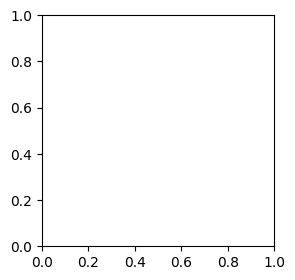

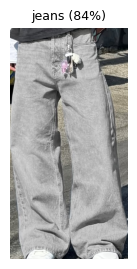

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


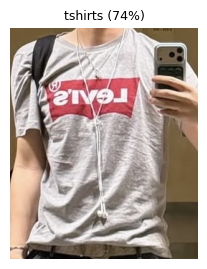

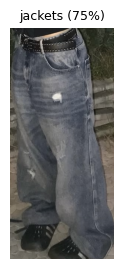

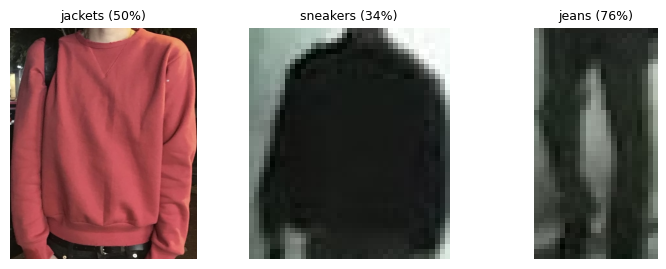

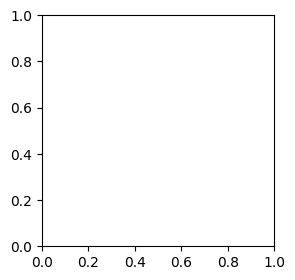

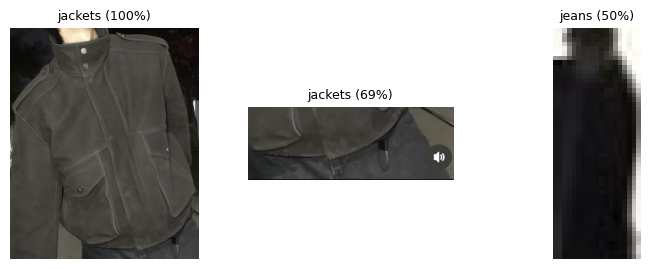

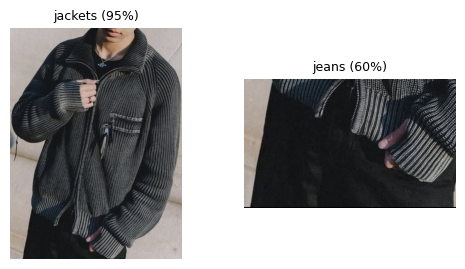

In [34]:
import glob
import numpy as np
for f in glob.glob("/content/*.jpg") + glob.glob("/content/*.png"):
  items = tag_outfit(Image.open(f))
  fig, axes = plt.subplots(1, max(len(items), 1), figsize=(3 * max(len(items), 1), 3))
  for ax, (crop, label) in zip(np.atleast_1d(axes), items):
    ax.imshow(crop); ax.set_title(label, fontsize=9); ax.axis("off")
  plt.show()

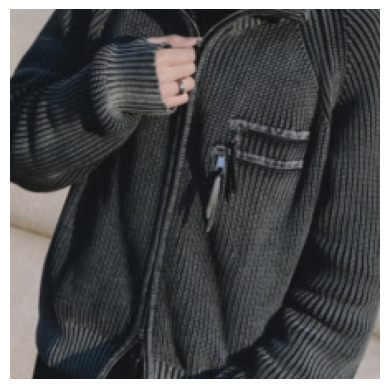

In [29]:
crop = items[0][0]   # one of your jeans crops from tag_outfit
plt.imshow(show(eval_tf(crop))); plt.axis("off"); plt.show()

In [35]:
import gradio as gr

gr.Interface(
    fn=tag_outfit,
    inputs=gr.Image(type="pil", label="Upload an outfit"),
    outputs=gr.Gallery(label="Detected items", columns=4),
    title="Outfit Tagger",
    description="Finds each clothing item in a photo and labels it.",
).launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8eab50b8bdc1613c52.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
